# VAE for Bearing Vibration
**Author:** Min Khaung Min Lwin

**Dataset:** Paderborn Bearing Dataset on Zenodo (DOI 10.5281/zenodo.15845309), https://zenodo.org/records/15845309 .

This dataset was created by Lessmeier et al. (2016) at Paderborn University, and the Zenodo upload is a copy. Later these are re-upload by Jurgen van den Hoogen (Osnabrück University), and published July 2025 under a CC BY 4.0 licence for copy.

**Task type:** I'll train a 1D-convolutional VAE on vibration windows from the Paderborn University bearing dataset. The training will be on healthy K001–K004, test on unseen healthy K005–K006 and on real damage KA04/KA15/KA16 (outer race) and KI04/KI14/KI16 (inner race).

With this we can generate new signals, explore the latent space, and test whether reconstruction error separates healthy from damaged bearings. 


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch
from scipy.io import loadmat
from pathlib import Path

DATA = Path("data/paderborn")
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(torch.__version__, device)

f = DATA / "K001" / "N15_M07_F10_K001_1.mat"
m = loadmat(f, simplify_cells=True)
print([k for k in m if not k.startswith("__")])
rec = m[f.stem]
print(type(rec), rec.keys() if isinstance(rec, dict) else "")
for ch in rec["Y"]:
    print(ch["Name"], np.asarray(ch["Data"]).shape)

2.15.0 mps
['N15_M07_F10_K001_1']
<class 'dict'> dict_keys(['Info', 'X', 'Y', 'Description'])
force (16001,)
phase_current_1 (256001,)
phase_current_2 (256001,)
speed (16001,)
temp_2_bearing_module (5,)
torque (16001,)
vibration_1 (256001,)


#### Note: I will load every file and look at the signals

In [2]:
BEARINGS = {"K001": "healthy", "K002": "healthy", "K003": "healthy", "K004": "healthy",
            "K005": "healthy", "K006": "healthy",
            "KA04": "outer_race", "KA15": "outer_race", "KA16": "outer_race",
            "KI04": "inner_race", "KI14": "inner_race", "KI16": "inner_race"}
FS = 64000

def load_vibration(path):
    """Return the vibration_1 channel of one Paderborn recording as float32."""
    rec = loadmat(path, simplify_cells=True)[path.stem]
    ch = next(c for c in rec["Y"] if c["Name"] == "vibration_1")
    return np.asarray(ch["Data"], dtype=np.float32)

signals, rows = {}, []
for b, label in BEARINGS.items():
    for f in sorted((DATA / b).glob("N15_M07_F10_*.mat")):
        x = load_vibration(f)
        signals[f.stem] = x
        rows.append({"file": f.stem, "bearing": b, "label": label, "n": len(x),
                     "rms": float(np.sqrt(np.mean(x**2))), "kurtosis": float(pd.Series(x).kurt())})
meta = pd.DataFrame(rows)
print(len(meta), "recordings")
meta.groupby(["label", "bearing"])[["n", "rms", "kurtosis"]].mean().round(3)

240 recordings


n    rms  kurtosis
label      bearing                            
healthy    K001     256261.75  0.403    10.687
           K002     257121.15  0.230    12.033
           K003     256760.60  0.362    12.788
           K004     256001.00  0.171     2.118
           K005     256259.45  0.199     1.215
           K006     256903.45  0.381    11.760
inner_race KI04     256181.40  0.365     2.202
           KI14     257635.05  0.227     0.806
           KI16     256932.10  0.390     2.081
outer_race KA04     256385.70  0.484     2.621
           KA15     256000.75  0.208     1.363
           KA16     256269.55  0.600     3.012

In [3]:
import os; os.makedirs("figures", exist_ok=True)

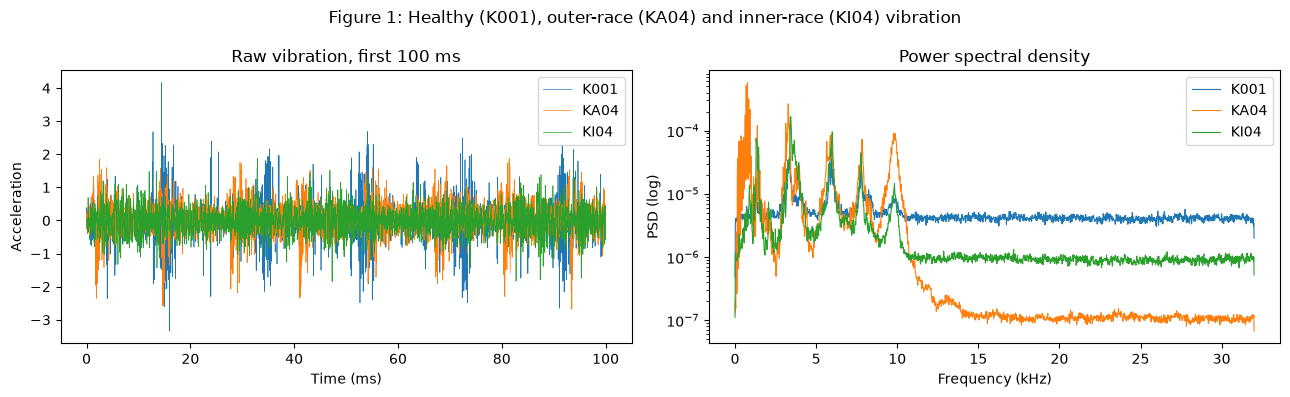

In [4]:
# Figure 1: raw vibration (first 0.1 s) and average spectrum for one bearing per class
from scipy.signal import welch
examples = ["N15_M07_F10_K001_1", "N15_M07_F10_KA04_1", "N15_M07_F10_KI04_1"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in examples:
    x = signals[name]
    t = np.arange(6400) / FS
    axes[0].plot(t * 1000, x[:6400], lw=0.5, label=name.split("_")[-2])
    f, p = welch(x, fs=FS, nperseg=4096)
    axes[1].semilogy(f / 1000, p, lw=0.8, label=name.split("_")[-2])
axes[0].set_title("Raw vibration, first 100 ms"); axes[0].set_xlabel("Time (ms)"); axes[0].set_ylabel("Acceleration")
axes[1].set_title("Power spectral density"); axes[1].set_xlabel("Frequency (kHz)"); axes[1].set_ylabel("PSD (log)")
for ax in axes: ax.legend()
plt.suptitle("Figure 1: Healthy (K001), outer-race (KA04) and inner-race (KI04) vibration")
plt.tight_layout(); plt.savefig("figures/fig1_samples.png", dpi=150); plt.show()

#### Interpretation of Figure 1

**Raw signal:** the healthy bearing K001 actually has the sharpest spikes of the three. Its kurtosis is about 10.7, against 2.2 for KI04 and 2.6 for KA04. So spikiness is not a damage signal in this data. It changes from bearing to bearing for other reasons.

**Spectrum:** all three bearings share the same resonance peaks near 1, 3.3, 6, 7.8 and 10 kHz. The damaged bearings have stronger peaks, especially KA04 near 1 kHz and 10 kHz. Above about 11 kHz the spectrum is a flat noise floor. K001's floor is roughly 4× higher than KI04's and 40× higher than KA04's. If that floor follows the bearing or the recording session rather than the damage, a model could separate the classes for the wrong reason. The next cell checks this, and it is why I later keep only 0–10 kHz.

**Limitation:** this figure shows one recording per class, so it only shows what to look for. It does not prove anything about the classes.

#### Now we will check whether these patterns follow the bearing or the session.

In [5]:
from scipy.signal import welch
diag = []
for _, r in meta.iterrows():
    f, p = welch(signals[r["file"]], fs=FS, nperseg=4096)
    diag.append({"bearing": r["bearing"], "label": r["label"],
                 "log_floor_15_30k": np.log10(p[(f > 15000) & (f < 30000)].mean()),
                 "log_band_0_10k": np.log10(p[f < 10000].mean()),
                 "kurtosis": r["kurtosis"]})
diag = pd.DataFrame(diag)
diag.groupby(["label", "bearing"]).agg(["mean", "std"]).round(2)

log_floor_15_30k       log_band_0_10k       kurtosis      
                               mean   std           mean   std     mean   std
label      bearing                                                           
healthy    K001               -5.40  0.02          -5.14  0.01    10.69  0.48
           K002               -6.08  0.02          -5.47  0.01    12.03  0.76
           K003               -5.46  0.01          -5.27  0.01    12.79  0.69
           K004               -6.60  0.01          -5.64  0.01     2.12  0.11
           K005               -6.57  0.01          -5.48  0.01     1.21  0.10
           K006               -5.44  0.02          -5.20  0.01    11.76  0.50
inner_race KI04               -5.96  0.11          -4.97  0.02     2.20  0.26
           KI14               -6.64  0.02          -5.35  0.01     0.81  0.11
           KI16               -6.53  0.01          -4.85  0.01     2.08  0.10
outer_race KA04               -6.94  0.02          -4.65  0.01     2.62  0.11
           KA15               -6.59  0.05          -5.46  0.01     1.36  0.21
           KA16               -6.77  0.04          -4.49  0.04     3.01  1.70

#### We'll build the spectrum dataset

In [6]:
WIN, NBIN_AVG, FMAX = 4096, 5, 10000      # 64 ms windows; 15.6 Hz bins averaged 5 at a time = 78 Hz; keep 0–10 kHz

def window_spectra(x):
    """Cut a signal into non-overlapping windows and return log power spectra (0–10 kHz, 128 bins)."""
    n = len(x) // WIN
    w = x[: n * WIN].reshape(n, WIN) * np.hanning(WIN)
    p = np.abs(np.fft.rfft(w, axis=1)) ** 2
    keep = int(FMAX / (FS / WIN))                       # 640 bins up to 10 kHz
    p = p[:, 1: keep + 1].reshape(n, -1, NBIN_AVG).mean(axis=2)   # drop DC, average to 128 bins
    return np.log10(p + 1e-12).astype(np.float32)

spec, spec_meta = [], []
for _, r in meta.iterrows():
    s = window_spectra(signals[r["file"]])
    spec.append(s); spec_meta += [{"bearing": r["bearing"], "label": r["label"], "file": r["file"]}] * len(s)
spec = np.concatenate(spec); spec_meta = pd.DataFrame(spec_meta)
print(spec.shape)
spec_meta.groupby(["label", "bearing"]).size()

(14903, 128)


label       bearing
healthy     K001       1240
            K002       1245
            K003       1243
            K004       1240
            K005       1240
            K006       1242
inner_race  KI04       1240
            KI14       1247
            KI16       1244
outer_race  KA04       1241
            KA15       1240
            KA16       1241
dtype: int64

#### Next step, we will split and standardise

In [7]:
rec_no = spec_meta["file"].str.split("_").str[-1].astype(int)
train_b = ["K001", "K002", "K003", "K004"]
is_train_b = spec_meta["bearing"].isin(train_b)

tr = is_train_b & (rec_no <= 16)          # training: recordings 1–16 of K001–K004
va = is_train_b & (rec_no > 16)           # validation: recordings 17–20 of the same bearings (monitoring only)
te = ~is_train_b                          # test: K005–K006 (healthy) and all damaged bearings, never seen

mu, sd = spec[tr].mean(axis=0), spec[tr].std(axis=0) + 1e-6   # per-bin statistics from training data only
Z = (spec - mu) / sd
print(tr.sum(), va.sum(), te.sum())

3970 998 9935


------

#### The VAE

In [8]:
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

class SpecVAE(nn.Module):
    """1D-convolutional VAE for 128-bin log power spectra."""
    def __init__(self, latent=8):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv1d(1, 16, 5, stride=2, padding=2), nn.LeakyReLU(0.2),   # 128 -> 64
            nn.Conv1d(16, 32, 5, stride=2, padding=2), nn.LeakyReLU(0.2),  # 64 -> 32
            nn.Conv1d(32, 64, 5, stride=2, padding=2), nn.LeakyReLU(0.2),  # 32 -> 16
            nn.Flatten())
        self.mu, self.logvar = nn.Linear(64 * 16, latent), nn.Linear(64 * 16, latent)
        self.fc = nn.Linear(latent, 64 * 16)
        self.dec = nn.Sequential(
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1), nn.LeakyReLU(0.2),  # 16 -> 32
            nn.ConvTranspose1d(32, 16, 4, stride=2, padding=1), nn.LeakyReLU(0.2),  # 32 -> 64
            nn.ConvTranspose1d(16, 1, 4, stride=2, padding=1))                      # 64 -> 128

    def encode(self, x):
        h = self.enc(x); return self.mu(h), self.logvar(h)

    def decode(self, z):
        return self.dec(self.fc(z).view(-1, 64, 16))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)   # reparameterisation trick
        return self.decode(z), mu, logvar

def vae_loss(x, xr, mu, logvar, beta=1.0):
    """Negative ELBO per sample: Gaussian reconstruction (sum of squared errors) + beta * KL."""
    rec = ((x - xr) ** 2).sum(dim=(1, 2)).mean()
    kl = (-0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(dim=1)).mean()
    return rec + beta * kl, rec, kl

def to_ds(mask):
    return TensorDataset(torch.tensor(Z[mask.values]).unsqueeze(1))

torch.manual_seed(0)
vae = SpecVAE(latent=8).to(device)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
train_loader = DataLoader(to_ds(tr), batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(0))
val_x = to_ds(va).tensors[0].to(device)

hist = []
for ep in range(60):
    vae.train(); tot = np.zeros(3); n = 0
    for (xb,) in train_loader:
        xb = xb.to(device); xr, m_, lv = vae(xb)
        loss, rec, kl = vae_loss(xb, xr, m_, lv)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += np.array([loss.item(), rec.item(), kl.item()]) * len(xb); n += len(xb)
    vae.eval()
    with torch.no_grad():
        vl, vr, vk = vae_loss(val_x, *vae(val_x))
    hist.append({"epoch": ep + 1, "train_loss": tot[0] / n, "train_rec": tot[1] / n, "train_kl": tot[2] / n,
                 "val_loss": vl.item(), "val_rec": vr.item(), "val_kl": vk.item()})
hist = pd.DataFrame(hist)
print(sum(p.numel() for p in vae.parameters()), "parameters")
hist.iloc[[0, 9, 29, 59]].round(2)

48961 parameters


,epoch,train_loss,train_rec,train_kl,val_loss,val_rec,val_kl
0,1,104.40,99.73,4.67,78.56,72.76,5.80
9,10,64.35,59.60,4.75,63.83,59.50,4.33
29,30,62.02,56.92,5.10,62.13,57.24,4.89
59,60,61.61,56.48,5.13,61.79,57.01,4.78


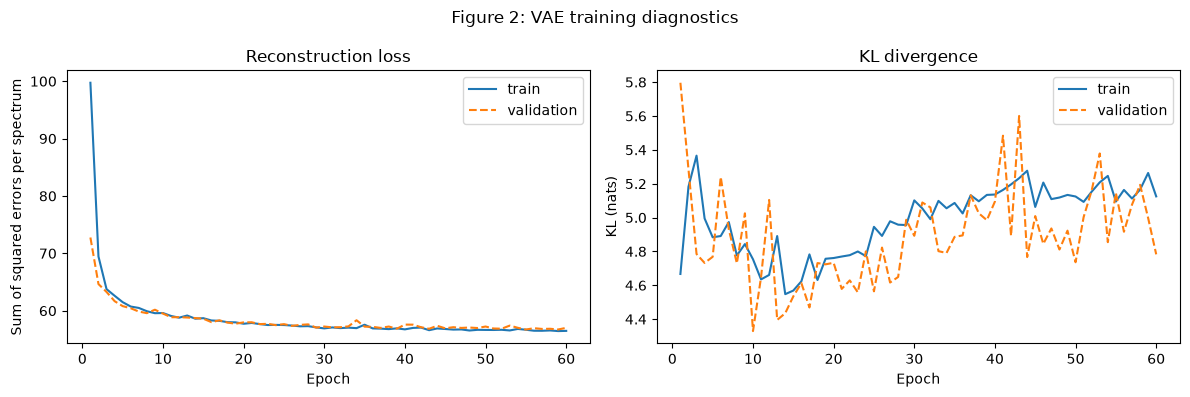

In [9]:
# Figure 2: training diagnostics
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["epoch"], hist["train_rec"], label="train"); axes[0].plot(hist["epoch"], hist["val_rec"], "--", label="validation")
axes[0].set_title("Reconstruction loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Sum of squared errors per spectrum")
axes[1].plot(hist["epoch"], hist["train_kl"], label="train"); axes[1].plot(hist["epoch"], hist["val_kl"], "--", label="validation")
axes[1].set_title("KL divergence"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("KL (nats)")
for ax in axes: ax.legend()
plt.suptitle("Figure 2: VAE training diagnostics"); plt.tight_layout()
plt.savefig("figures/fig2_training.png", dpi=150); plt.show()

#### Interpretation of Figure 2

**Strengths:** training is fast and stable. The reconstruction loss drops from about 100 to about 60 in the first 10 epochs, then flattens at 56.5 (train) and 57.0 (validation). The two curves lie on top of each other, so the model is not overfitting. (Validation is lower than training in epoch 1 only because the training loss is averaged over an epoch in which the weights are still improving.) The inputs are standardised, so a reconstruction error of 57 means the model explains a bit more than half of the per-bin variance. Much of the rest is bin-to-bin noise from the short 64 ms windows, which no model can predict.

**Challenges:** the KL term is noisy, moves between 4.3 and 5.8 nats, and creeps up slowly. The latent space has not collapsed, but it is used lightly. The per-dimension KL printed further down shows one dimension carrying 2.15 nats and the other seven only 0.24–0.8. With β = 1 and a summed squared error over 128 bins, reconstruction dominates the loss.

**Limitation:** the validation set is recordings 17–20 of the same four training bearings. These curves show the model fits K001–K004 well. They say nothing about how it handles a new bearing, which turns out to matter for K005 (Figure 4).

#### Prediction (written before training)

*Provenance: I wrote this cell and committed it (commit `9370025`) before the split, the VAE or any training code existed. I later moved it here, just before the evaluation cells, so it sits next to the results it predicts. The text has not been changed since that commit.*

If the VAE mainly learns overall loudness (the level of the 0–10 kHz spectrum), **KI14 and KA15 will be the hardest damaged bearings to detect.**

Why: in the diagnostics table above, their mean log power in the 0–10 kHz band (KI14 −5.35, KA15 −5.46) sits inside the range of the healthy training bearings K001–K004 (−5.64 to −5.14). The other damaged bearings are all louder than any healthy one (KI04 −4.97, KI16 −4.85, KA04 −4.65, KA16 −4.49), so a loudness-only model would flag them easily.

So if KI14 and KA15 do score close to healthy after training, the model is mostly reacting to loudness. If they are still separated well, it is picking up the shape of the spectrum, not just its level.

#### Now we will generate samples and evaluate them for the task 4.

In [10]:
from sklearn.metrics import roc_auc_score
from sklearn.decomposition import PCA
vae.eval()
freqs = (np.arange(128) + 0.5) * (FS / WIN) * NBIN_AVG / 1000     # bin centres in kHz
Xall = torch.tensor(Z).unsqueeze(1).to(device)
with torch.no_grad():
    mu_all, lv_all = vae.encode(Xall)
    recon = vae.decode(mu_all)                                    # deterministic reconstruction from the mean
    score = ((Xall - recon) ** 2).sum(dim=(1, 2)).cpu().numpy()   # anomaly score = reconstruction error
mu_all = mu_all.cpu().numpy()
spec_meta["score"] = score
spec_meta["band_power"] = spec.mean(axis=1)                       # mean log power 0–10 kHz (loudness)

# Which latent dimensions are active? (mean KL per dimension on training data)
kl_dim = (-0.5 * (1 + lv_all - torch.tensor(mu_all).to(device) ** 2 - lv_all.exp()))[tr.values].mean(0).cpu().numpy()
print("KL per latent dimension:", kl_dim.round(2))

KL per latent dimension: [0.56 0.25 0.31 2.15 0.24 0.31 0.8  0.29]


/var/folders/jk/1t31jnzx4wz_j0lvrst9hj1w0000gn/T/ipykernel_63872/3734673811.py:15: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  kl_dim = (-0.5 * (1 + lv_all - torch.tensor(mu_all).to(device) ** 2 - lv_all.exp()))[tr.values].mean(0).cpu().numpy()


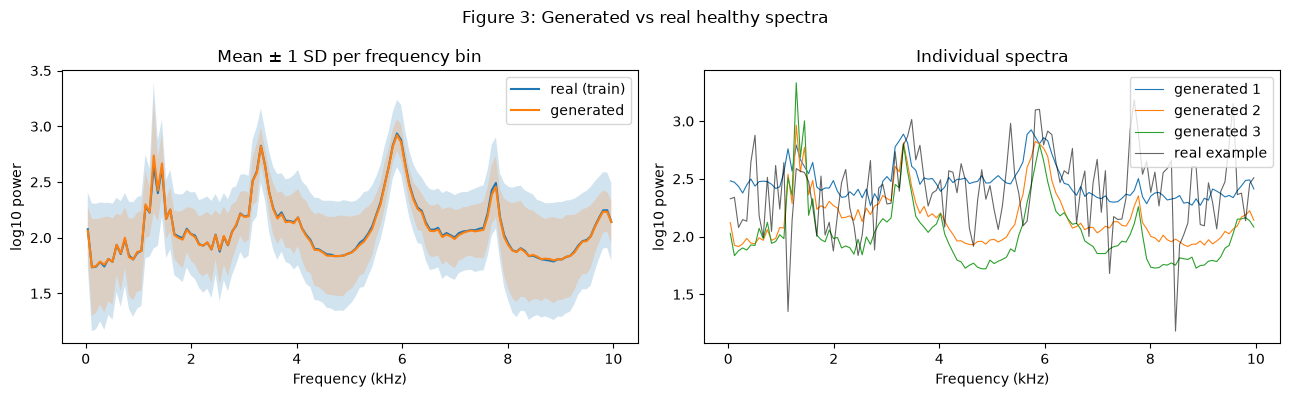

Mean per-bin SD  real: 0.421  generated: 0.279


Nearest-train distance  generated: 6.57  real validation: 8.82


In [11]:
# Figure 3: generated vs real healthy spectra
torch.manual_seed(1)
with torch.no_grad():
    gen = vae.decode(torch.randn(500, 8).to(device)).squeeze(1).cpu().numpy() * sd + mu
real = spec[tr.values]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for arr, lab in [(real, "real (train)"), (gen, "generated")]:
    m_, s_ = arr.mean(0), arr.std(0)
    axes[0].plot(freqs, m_, label=lab); axes[0].fill_between(freqs, m_ - s_, m_ + s_, alpha=0.2)
for i in range(3):
    axes[1].plot(freqs, gen[i], lw=0.8, label=f"generated {i+1}")
axes[1].plot(freqs, real[0], "k", lw=0.8, alpha=0.6, label="real example")
axes[0].set_title("Mean ± 1 SD per frequency bin"); axes[1].set_title("Individual spectra")
for ax in axes: ax.set_xlabel("Frequency (kHz)"); ax.set_ylabel("log10 power"); ax.legend()
plt.suptitle("Figure 3: Generated vs real healthy spectra"); plt.tight_layout()
plt.savefig("figures/fig3_generated.png", dpi=150); plt.show()

print("Mean per-bin SD  real:", real.std(0).mean().round(3), " generated:", gen.std(0).mean().round(3))
# Memorisation check: distance from each generated sample to its nearest training spectrum
from scipy.spatial.distance import cdist
d_gen = cdist((gen - mu) / sd, Z[tr.values]).min(1)
d_val = cdist(Z[va.values][:500], Z[tr.values]).min(1)
print("Nearest-train distance  generated:", np.median(d_gen).round(2), " real validation:", np.median(d_val).round(2))

In [12]:
# Memorisation check: if the VAE had memorised its training spectra, generated samples would sit closer to
# training windows than to held-out validation windows of the same bearings. The training set is subsampled
# to the validation size, because nearest-neighbour distances shrink as the reference set grows.
rng = np.random.default_rng(0)
gen_z = (gen - mu) / sd
tr_sub = Z[tr.values][rng.choice(tr.sum(), va.sum(), replace=False)]
d_tr, d_va = cdist(gen_z, tr_sub).min(1), cdist(gen_z, Z[va.values]).min(1)
print(f"Generated -> nearest train (n={len(tr_sub)}): median {np.median(d_tr):.2f}")
print(f"Generated -> nearest validation (n={va.sum()}): median {np.median(d_va):.2f}")
print(f"Share of generated samples closer to train than to validation: {(d_tr < d_va).mean():.1%}")

Generated -> nearest train (n=998): median 6.82
Generated -> nearest validation (n=998): median 6.74
Share of generated samples closer to train than to validation: 35.0%


#### Interpretation of Figure 3

**Strengths:** the mean of 500 generated spectra matches the real training mean almost exactly in every frequency bin. That includes the resonance peaks near 1.3, 3.3, 5.9 and 7.8 kHz and the dips between them. So the decoder has learned the overall shape of a healthy spectrum. Each generated sample also keeps the peaks at the right frequencies.

**Failure case – over-smoothing:** the generated spread is clearly too narrow. The average per-bin standard deviation is 0.279, against 0.421 for real spectra, or about two-thirds. The individual generated spectra are smooth curves. A real window jumps up and down by 0.5–1 log units from one bin to the next. This is the usual VAE behaviour. A Gaussian decoder trained with squared error learns to output the *average* spectrum for each latent code, and I plot the decoder mean without adding the noise term back. Fine random detail gets averaged away.

**Memorisation check:** the cell above compares each generated sample with equal-sized sets (998 windows each) of training and held-out validation spectra from the same four bearings. A model that memorised its training data would produce samples much closer to the training windows. They are not. The median nearest distance is 6.82 to training and 6.74 to validation, and only 35.0% of samples are closer to a training window than to a validation one, below the 50% you would expect if neither set were favoured. So the VAE has not memorised its training spectra: it generalises to unseen recordings of the same bearings as well as to the ones it trained on. (The earlier figure, a median of 6.57 against 8.82 for real validation spectra, shows something else. Generated samples sit nearer the training data than real new windows do, because smooth curves lie near the middle of the data cloud. That is the over-smoothing again, not copying.) The samples are believable as *average* healthy spectra, but not as realistic individual 64 ms windows.

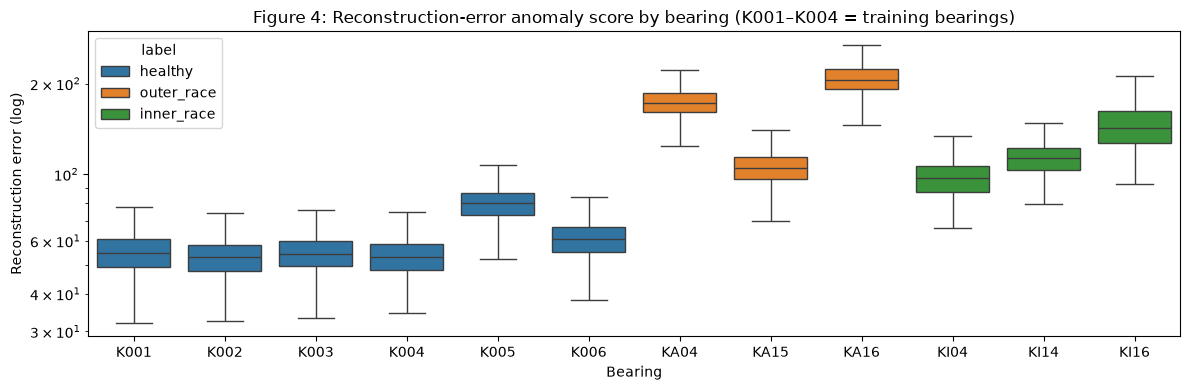

Correlation between score and loudness (all test windows): 0.66


,score,band_power,AUROC_vs_K005_K006
bearing,,,
K001,54.680000,2.41,NaN
K002,53.060001,1.90,NaN
K003,54.439999,2.29,NaN
K004,52.860001,1.71,NaN
K005,80.059998,1.81,NaN
K006,60.680000,2.34,NaN
KA04,172.669998,2.62,1.000
KA15,104.680000,1.87,0.965
KA16,206.320007,2.74,1.000


In [13]:
# Figure 4: anomaly score per bearing, plus detection quality (AUROC) for each damaged bearing
order = ["K001","K002","K003","K004","K005","K006","KA04","KA15","KA16","KI04","KI14","KI16"]
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=spec_meta, x="bearing", y="score", hue="label", order=order, showfliers=False, ax=ax)
ax.set_yscale("log"); ax.set_title("Figure 4: Reconstruction-error anomaly score by bearing (K001–K004 = training bearings)")
ax.set_xlabel("Bearing"); ax.set_ylabel("Reconstruction error (log)")
plt.tight_layout(); plt.savefig("figures/fig4_scores.png", dpi=150); plt.show()

healthy_test = spec_meta["bearing"].isin(["K005", "K006"])
auc = {b: roc_auc_score(np.r_[np.zeros(healthy_test.sum()), np.ones((spec_meta.bearing == b).sum())],
                        np.r_[score[healthy_test], score[spec_meta.bearing == b]])
       for b in ["KA04","KA15","KA16","KI04","KI14","KI16"]}
summary = spec_meta.groupby("bearing")[["score", "band_power"]].median().round(2)
summary["AUROC_vs_K005_K006"] = pd.Series(auc).round(3)
print("Correlation between score and loudness (all test windows):",
      np.corrcoef(spec_meta.loc[te, "score"], spec_meta.loc[te, "band_power"])[0, 1].round(2))
summary

In [14]:
# Alarm threshold set on held-out healthy data only (validation = recordings 17–20 of K001–K004, never trained on)
rows = []
for q in (95, 99):
    t = np.percentile(score[va.values], q)
    for b in ["K005", "K006", "KA04", "KA15", "KA16", "KI04", "KI14", "KI16"]:
        rows.append({"threshold": f"val p{q} = {t:.1f}", "bearing": b,
                     "flagged_%": 100 * (score[(spec_meta.bearing == b).values] > t).mean()})
alarms = pd.DataFrame(rows).pivot(index="bearing", columns="threshold", values="flagged_%").round(1)
alarms  # K005/K006 rows = false-alarm rate; damaged rows = detection rate

threshold,val p95 = 69.4,val p99 = 75.1
bearing,,
K005,84.8,67.5
K006,17.9,7.2
KA04,100.0,100.0
KA15,99.9,99.4
KA16,100.0,100.0
KI04,99.7,96.4
KI14,100.0,100.0
KI16,100.0,100.0


#### Interpretation of Figure 4 and the prediction result

**Strengths:** every damaged bearing has a higher median score than both unseen healthy bearings. The AUROC against K005/K006 is 0.916–1.000. KA04 and KA16 are separated perfectly, and KI16 almost perfectly (0.999). The model was never shown any damaged data, so all of this comes from learning what healthy looks like.

**Failure case – K005:** K005 is healthy, but its median score is 80. The training bearings score 53–55 and K006 scores 61. Its upper whisker reaches about 105, which overlaps the KA15 and KI04 boxes. The threshold table above measures the cost. I set the alarm threshold at the 95th or 99th percentile of the validation windows (held-out healthy recordings of K001–K004). Those thresholds flag **84.8% (p95) or 67.5% (p99) of K005's windows** as damaged, against 17.9% or 7.2% for K006, while still catching 96.4–100% of the windows of every damaged bearing. K005 is the quietest and least spiky healthy bearing (kurtosis 1.2), and only K004 in the training set resembles it. The model is partly measuring "unlike the four bearings I trained on", not just "damaged". (K001–K004 also include their own training windows, so their scores look better than a fair test. K005/K006 are the honest healthy baseline.)

**Prediction result – partly right:**

| Bearing | AUROC | Mean log power 0–10 kHz (`band_power`) |
|---|---|---|
| KI04 | 0.916 | 2.35 |
| KA15 | 0.965 | 1.87 |
| KI14 | 0.987 | 1.93 |
| KI16 | 0.999 | 2.42 |
| KA04 | 1.000 | 2.62 |
| KA16 | 1.000 | 2.74 |

**What the original prediction got right and wrong.** It named KA15 and KI14 as the hardest bearings. They came out second and third hardest. It missed the hardest one, **KI04** (AUROC 0.916), which it expected to be easy because KI04 was louder than every healthy bearing by the Welch measure. The prediction also set its own test: if KI14 and KA15 were "still separated well", the model was picking up spectral shape and not just loudness. With AUROCs of 0.987 and 0.965 they are separated well. So by the prediction's own criterion, the VAE is **not** a loudness-only detector, even though loudness clearly matters: the correlation between score and loudness on the test windows is 0.66.

**A post-hoc explanation, not a confirmation.** *After* seeing the results, I looked for why KI04 is hard. The Welch measure in the prediction is the log of the *mean* power, which the strong resonance peaks inflate. The VAE's input is closer to the *mean of the log* spectrum (the `band_power` column above). By that measure KI04 (2.35) falls inside the healthy training range (1.71–2.41), as do KA15 (1.87) and KI14 (1.93), and these are exactly the three lowest AUROCs. That is a neat fit. But I chose this measure after seeing which bearings were hard, so it is a **hypothesis to test, not a confirmation**. Six damaged bearings are too few to tell a real pattern from a lucky choice of measure. A fair test would fix `band_power` as the loudness measure *now* and check it on damaged bearings the model has not seen, for example other Paderborn bearings such as KA22, KA30, KI17, KI18 and KI21, before computing their scores.

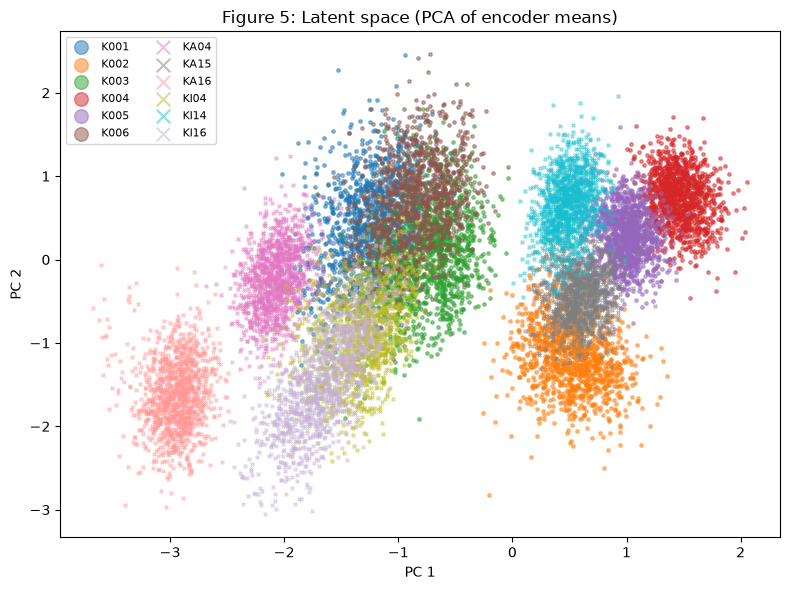

In [15]:
# Figure 5: latent space (PCA of the encoder means), coloured by bearing
pc = PCA(2).fit(mu_all[tr.values]).transform(mu_all)
# tab20 gives 12 distinguishable colours; KA16 and KI16 reuse a light shade of K004's / K005's hue, which lie far apart in the plot
colours = dict(zip(order, [plt.cm.tab20(i) for i in (0, 2, 4, 6, 8, 10, 12, 14, 7, 16, 18, 9)]))
fig, ax = plt.subplots(figsize=(8, 6))
for b in order:
    idx = (spec_meta.bearing == b).values
    ax.scatter(pc[idx, 0], pc[idx, 1], s=6, alpha=0.5, color=colours[b], label=b, marker="o" if b.startswith("K0") else "x")
ax.set_title("Figure 5: Latent space (PCA of encoder means)"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
ax.legend(markerscale=4, ncol=2, fontsize=8); plt.tight_layout()
plt.savefig("figures/fig5_latent.png", dpi=150); plt.show()

In [16]:
pos = pd.DataFrame({"bearing": spec_meta.bearing, "pc1": pc[:, 0], "band_power": spec_meta.band_power}).groupby("bearing").mean()
print("Correlation of mean PC1 with mean loudness across bearings:", pos.corr().iloc[0, 1].round(2)); pos.round(2)

Correlation of mean PC1 with mean loudness across bearings: -0.99


,pc1,band_power
bearing,,
K001,-1.26,2.41
K002,0.52,1.91
K003,-0.72,2.30
K004,1.46,1.71
K005,0.99,1.81
K006,-0.86,2.34
KA04,-2.07,2.62
KA15,0.59,1.88
KA16,-2.95,2.74


#### Interpretation of Figure 5

**What the axes mean:** PC 1 is essentially loudness. Across the 12 bearings, the correlation between a bearing's mean PC 1 and its mean `band_power` is **−0.99** (table above). PC 1 runs from loud (left) to quiet (right). The quiet bearings `K004, K005, KA15, K002` and `KI14` sit on the right. The loud bearings `K003, K006, K001, KI04, KI16, KA04` and `KA16` sit on the left, and the loudest damaged bearing, `KA16`, is furthest out. PC 2 partly carries damage: within each group, most damaged bearings (`KA16, KI16, KI04, KA15`) sit lower than the healthy bearings around them. It is not clean, though. `KI14` sits high, next to `K004` and `K005`, and the healthy bearing `K002` sits low.

**Strengths:** the latent space is smooth and well organised. Each bearing forms its own compact cluster, and the loudest damaged bearings fall outside the area covered by any healthy bearing, which is why they reach AUROC 1.0.

**Failure cases:** the latent space is organised by *bearing and loudness*, not by healthy vs damaged. There is no single "damaged" region. This fits the original prediction: KI14 and KA15, the two bearings it named, sit right next to the quiet healthy bearings K002, K004 and K005. (PC 1 also tracks `band_power`, the post-hoc measure from Figure 4, so this is not independent support for that measure.) It also explains K005. It lies inside the quiet healthy group, between K004 and KI14, in a region the training data covers only through K004. Detection therefore depends on reconstruction error, not on where a window lands in the latent space.

## Summary

I trained a small 1D-convolutional VAE (8 latent dimensions, about `49k` parameters) on `0–10` kHz log power spectra of 64 ms vibration windows from four healthy Paderborn bearings. I then used it to generate new healthy spectra and to score unseen bearings by reconstruction error. 

The generated spectra reproduce the average healthy shape and its resonance peaks almost exactly, but they are over-smoothed: their spread is only about two-thirds of the real spread, and they lack the sharp bin-to-bin detail of real windows. 

Through out the process, the training was stable, with validation loss tracking training loss, but the KL term stayed small (about `5` nats) and most of it sits in one latent dimension, and the validation split only contains new recordings of the training bearings. 

As an anomaly detector the VAE separates all six damaged bearings from unseen healthy `K005/K006` (AUROC `0.92`–`1.00`), but its latent space is organised mainly by loudness and by bearing. My prediction, written before training, named KA15 and KI14 as the hardest damaged bearings. They came out second and third hardest, but it missed the hardest, KI04. A loudness measure I chose after seeing the results explains all three, but because it was chosen afterwards, that is a hypothesis to test on new bearings, not a confirmation. 

The main failure mode is false alarms on healthy bearings unlike the training set: K005 scores about 50% higher than the training bearings, and a threshold at the 99th percentile of healthy validation windows flags 67.5% of its windows as damaged (84.8% at the 95th), so with only four healthy training bearings the model cannot fully tell "new bearing" from "damaged bearing".